In [3]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_excel("TicoShop_Clientes.xlsx")

df.head()

Saving TicoShop_Clientes.xlsx to TicoShop_Clientes (1).xlsx


,cliente_id,recencia,frecuencia,monto,antiguedad_meses,quejas,usa_app,se_fue
0,C0001,26,10,217500,35,0,0,0
1,C0002,33,5,346900,5,0,1,0
2,C0003,54,8,212800,29,0,0,0
3,C0004,17,2,116800,1,0,0,0
4,C0005,62,10,118300,40,0,0,0


In [4]:
#Paso 1 Explorar los datos

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#configuro los graficos
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

#veo cuantos clientes hay
print("Cantidad de clientes:", len(df))

#veo cuantos se quedaron y cuantos se fueron
print("\nClientes que se quedaron y se fueron:")
print(df["se_fue"].value_counts())

#lo veo tambien como porcentaje
print("\nPorcentaje:")
print((df["se_fue"].value_counts(normalize=True) * 100).round(1))

#comparo los promedios
comparacion = df.groupby("se_fue")[
    ["recencia", "frecuencia", "monto",
     "antiguedad_meses", "quejas", "usa_app"]
].mean()

print("\nComparacion de clientes:")
print(comparacion.round(2))

Cantidad de clientes: 2000

Clientes que se quedaron y se fueron:
se_fue
0    1570
1     430
Name: count, dtype: int64

Porcentaje:
se_fue
0    78.5
1    21.5
Name: proportion, dtype: float64

Comparacion de clientes:
        recencia  frecuencia      monto  antiguedad_meses  quejas  usa_app
se_fue                                                                    
0          37.05        9.95  318713.82             24.63    0.50     0.50
1         141.62        3.80   85118.60             28.67    1.14     0.33


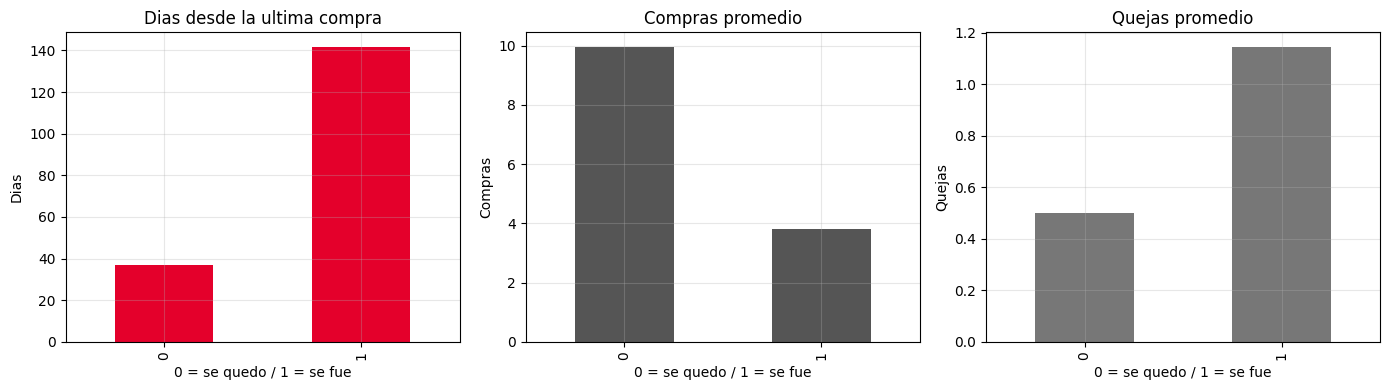

In [5]:
#graficos para comparar los clientes

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

#dias desde la ultima compra
df.groupby("se_fue")["recencia"].mean().plot.bar(
    ax=axes[0], color="#E4002B"
)
axes[0].set_title("Dias desde la ultima compra")
axes[0].set_xlabel("0 = se quedo / 1 = se fue")
axes[0].set_ylabel("Dias")

#cantidad de compras
df.groupby("se_fue")["frecuencia"].mean().plot.bar(
    ax=axes[1], color="#555555"
)
axes[1].set_title("Compras promedio")
axes[1].set_xlabel("0 = se quedo / 1 = se fue")
axes[1].set_ylabel("Compras")

#cantidad de quejas
df.groupby("se_fue")["quejas"].mean().plot.bar(
    ax=axes[2], color="#777777"
)
axes[2].set_title("Quejas promedio")
axes[2].set_xlabel("0 = se quedo / 1 = se fue")
axes[2].set_ylabel("Quejas")

plt.tight_layout()
plt.show()

Al comparar los clientes, se observa que los que dejaron de comprar llevaban aproximadamente 142 días sin hacer una compra, mientras que los que se quedaron tenían un promedio de 37 días. Además, los clientes que se quedaron compraban unas 10 veces y los que se fueron solo unas 4 veces. También se encontró que los clientes que se fueron tenían más quejas. Esto muestra que pasar mucho tiempo sin comprar, comprar poco y tener más quejas pueden ser señales de que un cliente podría dejar de comprar.

In [6]:
#Paso 2 Crear segmentos de clientes

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

#escojo las variables para crear los grupos
columnas = [
    "recencia",
    "frecuencia",
    "monto",
    "antiguedad_meses",
    "quejas",
    "usa_app"
]

datos = df[columnas]

#pongo los datos en una escala parecida
scaler = StandardScaler()
datos_escalados = scaler.fit_transform(datos)

#creo 4 grupos de clientes
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

df["segmento"] = kmeans.fit_predict(datos_escalados)

#veo las caracteristicas de cada grupo
segmentos = df.groupby("segmento").agg(
    clientes=("cliente_id", "count"),
    recencia=("recencia", "mean"),
    frecuencia=("frecuencia", "mean"),
    monto=("monto", "mean"),
    antiguedad=("antiguedad_meses", "mean"),
    quejas=("quejas", "mean"),
    usa_app=("usa_app", "mean"),
    abandono=("se_fue", "mean")
)

#paso el abandono a porcentaje
segmentos["abandono"] = segmentos["abandono"] * 100

print("Segmentos encontrados:")
print(segmentos.round(2))

Segmentos encontrados:
          clientes  recencia  frecuencia      monto  antiguedad  quejas  \
segmento                                                                  
0              582     44.49        6.35  171640.21       22.70    0.47   
1              348    173.05        3.20   50498.56       34.43    1.69   
2              287      9.62       25.46  952800.70       28.39    0.40   
3              783     38.57        6.57  186538.70       22.54    0.39   

          usa_app  abandono  
segmento                     
0            1.00     10.82  
1            0.32     70.69  
2            0.82      0.70  
3            0.00     15.20  


nombre_segmento
Clientes tradicionales    783
Clientes digitales        582
Clientes en riesgo        348
Clientes de alto valor    287
Name: count, dtype: int64


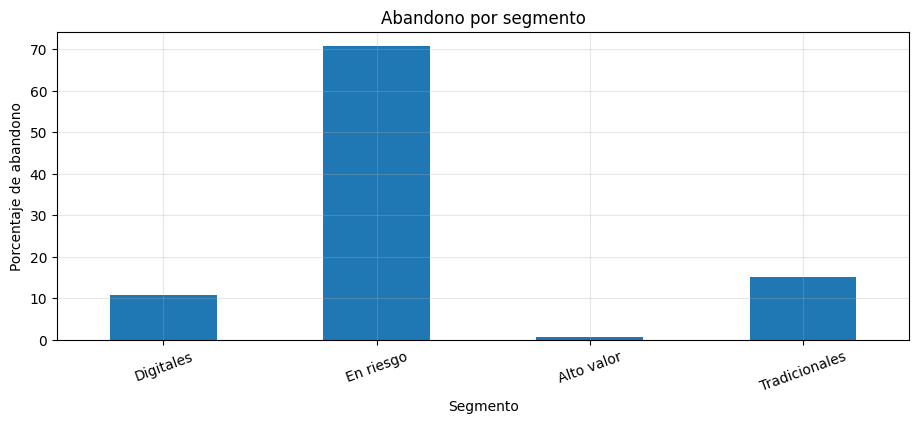

In [7]:
#pongo un nombre a cada segmento segun sus caracteristicas

nombres = {
    0: "Clientes digitales",
    1: "Clientes en riesgo",
    2: "Clientes de alto valor",
    3: "Clientes tradicionales"
}

df["nombre_segmento"] = df["segmento"].map(nombres)

#veo cuantos clientes hay en cada grupo
print(df["nombre_segmento"].value_counts())

#comparo el abandono de los segmentos

segmentos["abandono"].plot.bar()

plt.title("Abandono por segmento")
plt.xlabel("Segmento")
plt.ylabel("Porcentaje de abandono")
plt.xticks(
    [0, 1, 2, 3],
    ["Digitales", "En riesgo", "Alto valor", "Tradicionales"],
    rotation=20
)

plt.show()

Se crearon cuatro grupos de clientes. Los clientes digitales son 582 y utilizan la aplicación. Los clientes en riesgo son 348, compran poco, tienen más quejas y llevan mucho tiempo sin comprar. Los clientes de alto valor son 287 y se caracterizan por comprar más y gastar más. Por último, los clientes tradicionales son 783 y no utilizan la aplicación.

In [8]:
#Paso 3 Predecir que clientes pueden dejar de comprar

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix

#x son las variables que voy a usar para predecir
X = df[
    ["recencia", "frecuencia", "monto",
     "antiguedad_meses", "quejas", "usa_app"]
]

#y es lo que quiero predecir
#0 = se quedo y 1 = se fue
y = df["se_fue"]

#separo 70% para entrenar y 30% para probar
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

#pongo las variables en una escala parecida
scaler_modelo = StandardScaler()

X_train_escalado = scaler_modelo.fit_transform(X_train)
X_test_escalado = scaler_modelo.transform(X_test)

#creo y entreno el modelo
modelo = LogisticRegression(
    class_weight="balanced",
    random_state=42
)

modelo.fit(X_train_escalado, y_train)

#hago las predicciones
prediccion = modelo.predict(X_test_escalado)
probabilidad = modelo.predict_proba(X_test_escalado)[:, 1]

#veo los resultados
print("Accuracy:", round(accuracy_score(y_test, prediccion), 3))
print("Precision:", round(precision_score(y_test, prediccion), 3))
print("Recall:", round(recall_score(y_test, prediccion), 3))
print("AUC:", round(roc_auc_score(y_test, probabilidad), 3))

print("\nMatriz de confusion:")
print(confusion_matrix(y_test, prediccion))

Accuracy: 0.805
Precision: 0.533
Recall: 0.744
AUC: 0.863

Matriz de confusion:
[[387  84]
 [ 33  96]]


Se usó una regresión logística para identificar los clientes que podrían dejar de comprar. El modelo acertó un 80,5 % y detectó el 74,4 % de los clientes que se fueron. Esto puede ayudar a TicoShop a identificar clientes en riesgo y contactarlos a tiempo.

Factores relacionados con el riesgo:
frecuencia         -1.301610
usa_app            -0.319424
monto              -0.043127
antiguedad_meses   -0.020353
quejas              0.404846
recencia            1.153501
dtype: float64


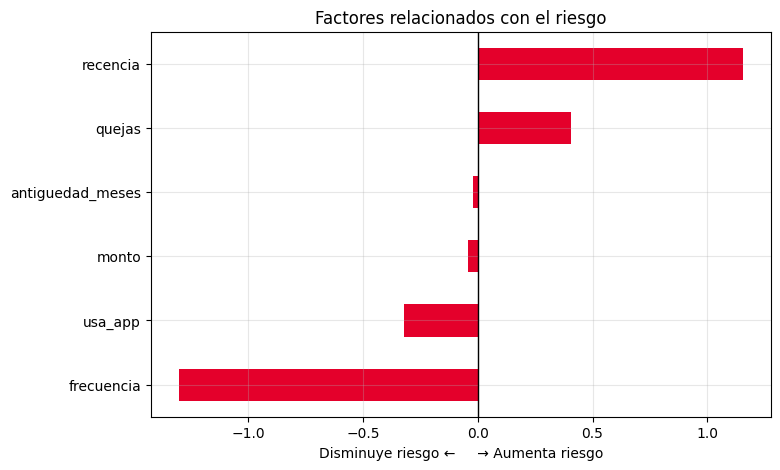

In [9]:
#Paso 4 Ver que factores aumentan o disminuyen el riesgo

#obtengo los valores que aprendio el modelo
coef = pd.Series(
    modelo.coef_[0],
    index=X.columns
).sort_values()

print("Factores relacionados con el riesgo:")
print(coef)

#los muestro en un grafico
coef.plot.barh(
    figsize=(8, 5),
    color="#E4002B"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Factores relacionados con el riesgo")
plt.xlabel("Disminuye riesgo ←     → Aumenta riesgo")

plt.show()

Los resultados muestran que los clientes que llevan más tiempo sin comprar y tienen más quejas tienen mayor riesgo de irse. En cambio, los clientes que compran con frecuencia y usan la aplicación tienen menor riesgo. Por eso, TicoShop debería prestar más atención a los clientes que llevan mucho tiempo sin comprar o tienen quejas.

In [10]:
#Paso 5 Buscar los clientes que necesitan mas atencion

#calculo el riesgo para todos los clientes
X_todos = scaler_modelo.transform(X)

df["riesgo"] = modelo.predict_proba(X_todos)[:, 1]

#lo convierto a porcentaje
df["riesgo_porcentaje"] = (df["riesgo"] * 100).round(1)

#ordeno los clientes de mayor a menor riesgo
prioridad = df[
    ["cliente_id", "recencia", "frecuencia",
     "monto", "quejas", "nombre_segmento",
     "riesgo_porcentaje"]
].sort_values(
    "riesgo_porcentaje",
    ascending=False
)

print("Clientes que se deberian contactar primero:")

prioridad.head(20)

Clientes que se deberian contactar primero:


,cliente_id,recencia,frecuencia,monto,quejas,nombre_segmento,riesgo_porcentaje
851,C0852,365,2,30500,3,Clientes en riesgo,99.9
352,C0353,365,1,13900,3,Clientes en riesgo,99.9
1213,C1214,365,1,14000,2,Clientes en riesgo,99.8
1211,C1212,326,4,81700,5,Clientes en riesgo,99.7
1824,C1825,365,4,77300,2,Clientes en riesgo,99.7
1288,C1289,321,1,11200,2,Clientes en riesgo,99.6
766,C0767,365,3,61800,1,Clientes en riesgo,99.6
305,C0306,362,1,12700,2,Clientes en riesgo,99.6
808,C0809,360,2,35100,1,Clientes en riesgo,99.6
1532,C1533,356,2,30200,1,Clientes en riesgo,99.6


Plan de acción para TicoShop

TicoShop debería contactar primero a los clientes que llevan mucho tiempo sin comprar y a los que han presentado varias quejas, ya que son los que tienen mayor posibilidad de dejar de comprar.

Se les puede ofrecer un descuento, envío gratis o alguna promoción para motivarlos a volver. Si el cliente ha presentado una queja, sería bueno contactarlo para conocer qué pasó y tratar de solucionar el problema.

También se pueden dar beneficios especiales a los clientes que compran seguido para mantenerlos satisfechos y lograr que continúen comprando en TicoShop.